Folie 23: Hausaufgabe

In [1]:
"""
Package for calculations with Vectors
"""
from __future__ import annotations
import doctest
import math


class Vector:

    def __init__(self, values: list[int | float]):
        """
        Initialises the array
        :param values: a list of numbers
        """
        self.values = values

    def dimension(self) -> int:
        """
        Returns the dimension of the vector
        :return: int
        """
        return len(self.values)

    def length(self) -> float:
        """
        returns the length of the vector
        :return: float

        >>> a = Vector([2,2,2,2])
        >>> a.length()
        4.0
        """
        return math.sqrt(sum([x**2 for x in self.values]))

    def __str__(self) -> str:
        return str(self.values)

    def __repr__(self) -> str:
        return self.__str__()

    def __eq__(self, other: Vector) -> bool:
        """
        Compares two vectors elementwise
        :param other: Vector
        :return: bool

        >>> Vector([0,1])== Vector([0.0,1])
        True

        >>> Vector([0,2])== Vector([0,1])
        False
        """
        if type(other) != Vector:
            raise TypeError("Other is no Vector!")
        else:
            return all(list(map(lambda x, y: x == y, self.values, other.values)))

    def __add__(self, other: Vector | int | float) -> Vector:
        """
        Adds other to self.values and return a new Vector
        :param other: Vector, int or float
        :return: Vector

        >>> str(Vector([5,6])+Vector([0,1]))
        '[5, 7]'

        >>> str(Vector([5,6])+ 8.3)
        '[13.3, 14.3]'
        """
        if type(other) == Vector:
            values = list(map(lambda x, y: x + y, self.values, other.values))
        elif type(other) in (int, float):
            values = [x+other for x in self.values]
        else:
            raise TypeError(f"{type(other)} is not valid!")
        return Vector(values)

    def __radd__(self, other: int | float) -> Vector:
        """
        Adds other to self.values and return a new Vector when other is a number and on the left side of the quotation
        e.g. a = other + Vector()
        :param other: int or float
        :return: Vector

        >>> a = 5 + Vector([0,1])
        >>> str(a)
        '[5, 6]'
        """
        return self.__add__(other)

    def __mul__(self, other: int | float) -> Vector:
        """
        Multiplies a Scalar and a Vector
        :param other: int or float or                    vor
        :return: Vector or float

        >>> str(Vector([5,6])*2)
        '[10, 12]'
        """
        if type(other) in (int, float):
            values = [x*other for x in self.values]
        else:
            raise TypeError(f"{type(other)} is not valid!")
        return Vector(values)

    def __rmul__(self, other: int | float) -> Vector:
        """
        Multiplies other to self.values and return a new Vector other beeing on the left side of the quotation
        e.g. a = other * Vector()
        :param other: int or float
        :return: Vector

        >>> a = 5 * Vector([0,1])
        >>> str(a)
        '[0, 5]'
        """
        return self.__mul__(other)

    def __sub__(self, other: Vector | int | float) -> Vector:
        """
        Adds other to self.values and return a new Vector
        :param other: Vector, int or float
        :return: Vector

        >>> str(Vector([5,6])-Vector([0,1]))
        '[5, 5]'

        >>> str(Vector([5,6])- 8)
        '[-3, -2]'
        """
        return self.__add__(-1 * other)

    def rotate(self, angle: int | float, radians: bool = True) -> str:
        """
        Rotate Vector by angle in degrees or radians
        :param angle: in degrees or radians
        :param radians: if True angle is in radians else in degrees
        :return: string output of new vector

        >>> a = Vector([0,1])
        >>> str(a.rotate(math.pi))
        '[1.2246467991473532e-16, -1.0]'

        >>> a = Vector([0,1])
        >>> str(a.rotate(90, radians=False))
        '[1.0, 6.123233995736766e-17]'

        """
        if not radians:
            angle = angle * math.pi/180
        self.values = [math.sin(angle)*self.length(), math.cos(angle)*self.length()]
        return str(self)

    def __matmul__(self, other):
        """
        Calculates the scalar product of two vectors
        :param other: Vector
        :return: Vector

        >>> Vector([0,1])@Vector([1,0])
        0.0

        >>> Vector([5,2])@Vector([1,7])
        19.0
        """
        if type(other) == Vector:
            return float(sum(map(lambda x, y: x * y, self.values, other.values)))
        else:
            raise TypeError(f"{type(other)} is not valid!")

    def get_angle_between(self, other: Vector, radians: bool = True) -> float:
        """
        Returns the angle in radians or degrees between self and other
        :param other: Vector
        :param radians: if True angle is in radians else in degrees
        :return: float (angle in degree or radians)

        >>> Vector([0,1]).get_angle_between(Vector([1,0]), radians=False)
        90.0

        >>> Vector([0,1]).get_angle_between(Vector([-1,0]), radians=False)
        -90.0

        >>> Vector([0,1]).get_angle_between(Vector([0,-9]), radians=False)
        180.0

        >>> Vector([0,1]).get_angle_between(Vector([1,1]))
        0.7853981633974484

        """
        angle = math.acos((self @ other) / (self.length() * other.length()))
        if not radians:
            angle *= 180/math.pi
        if other.values[0] < self.values[0]:
            angle *= -1
        return angle


if __name__ == "__main__":
    doctest.testmod()

In [24]:
import math

#from vector import Vector
from random import random


class SpinningObserverProblem:

    def __init__(self, size: tuple[int | float], amount_opponents: int = 10):
        self.observer_position, self.opponents_positions = self.create_board(size, amount_opponents)

    @staticmethod
    def create_board(size, amount_opponents):
        observer_position = Vector([random() * size[0], random() * size[1]])
        positions_used = [observer_position]
        opponents_positions = []
        for opponent in range(amount_opponents):
            pos = Vector([random() * size[0], random() * size[1]])
            while pos in positions_used:
                pos = Vector([random() * size[0], random() * size[1]])
            opponents_positions.append(pos)
            positions_used.append(pos)
        return observer_position, opponents_positions

    def start(self, observer_angle, rotation_speed, opponent_speed):
        """
        Calculates if the observer looking in a direction of "observer_angle" turning clockwise with "rotation_speed"
        sees all opponent before they reach him with "opponent_speed"
        :param observer_angle: angle in degrees of the abserver
        :param rotation_speed: degrees per timestep in float
        :param opponent_speed: length per timestep in float
        :return: bool
        """
        # shift board to origin around observer calc angle to opponent and add angle of observer to (0,1)
        observer_angle *= math.pi / 180
        rotation_speed *= math.pi / 180
        shifted_opponents: list[tuple[Vector, float]] = []
        for opponent in self.opponents_positions:
            opponent -= self.observer_position
            angle_to_opponent = Vector([0, 1]).get_angle_between(opponent) + observer_angle
            angle_to_opponent if angle_to_opponent >= 0 else angle_to_opponent + 2 * math.pi
            shifted_opponents.append((opponent, angle_to_opponent))
        # sort due to angle from observer
        # shifted_opponents.sort(key=lambda elem: elem[1])

        # calculate who is faster
        caught = [(opponents[1] / rotation_speed) >= (abs(opponents[0].length()) / opponent_speed)
                  for opponents in shifted_opponents]
        if not any(caught):
            return True
        else:
            print(f"Observer {self.observer_position} caught {sum(caught)} times "
                  f"by opponents {[i for (i, v) in zip(self.opponents_positions, caught) if v]} "
                  f"of all opponents {self.opponents_positions}!")
            return False


sop = SpinningObserverProblem((10, 10), 10)
sop.start(0, 1, 1)


Observer [0.5287701520262955, 9.801769290802156] caught 10 times by opponents [[8.031455326145752, 3.253596142770431], [7.642847303128322, 5.52248626708089], [0.940621123978953, 9.04267622345481], [6.339472282675652, 1.439461138454724], [9.70998125685245, 5.756155872221114], [5.297835242847302, 1.608563189083625], [0.7207988408215771, 9.998321567225494], [6.511350671069344, 1.921552084056799], [1.2749704336632373, 2.8888986944458606], [2.238459650749153, 6.730342675597115]] of all opponents [[8.031455326145752, 3.253596142770431], [7.642847303128322, 5.52248626708089], [0.940621123978953, 9.04267622345481], [6.339472282675652, 1.439461138454724], [9.70998125685245, 5.756155872221114], [5.297835242847302, 1.608563189083625], [0.7207988408215771, 9.998321567225494], [6.511350671069344, 1.921552084056799], [1.2749704336632373, 2.8888986944458606], [2.238459650749153, 6.730342675597115]]!


False

Folie 29

In [27]:
from timeit import Timer
import numpy as np

size_of_vector = 1000

def pure_python_version():
    X = range(size_of_vector)
    Y = range(size_of_vector)
    Z = [X[i]+Y[i] for i in range(size_of_vector)]
    
def numpy_version():
    X = np.arange(size_of_vector)
    Y = np.arange(size_of_vector)
    Z = X+Y
    
timer1 = Timer("pure_python_version()", "from __main__ import pure_python_version")
timer2 = Timer("numpy_version()", "from __main__ import numpy_version")

t1 = timer1.timeit(1000)
t2 = timer2.timeit(1000)

print (t1/t2)

print(timer1.repeat(repeat=10, number = 10))

22.904812889284248
[0.0007899999618530273, 0.0007647001184523106, 0.0007643001154065132, 0.0007603999692946672, 0.0007625001017004251, 0.0007631999906152487, 0.0007621000986546278, 0.0007621000986546278, 0.000754800159484148, 0.0007440999615937471]


Folie 30

In [32]:
a = np.arange(1,10,2,float)
b = np.arange(10)
print(a)
print(b)
a.dtype

[1. 3. 5. 7. 9.]
[0 1 2 3 4 5 6 7 8 9]


dtype('float64')

In [36]:
a, step = np.linspace(1,10,100,retstep = True)
print(a, step)

[ 1.          1.09090909  1.18181818  1.27272727  1.36363636  1.45454545
  1.54545455  1.63636364  1.72727273  1.81818182  1.90909091  2.
  2.09090909  2.18181818  2.27272727  2.36363636  2.45454545  2.54545455
  2.63636364  2.72727273  2.81818182  2.90909091  3.          3.09090909
  3.18181818  3.27272727  3.36363636  3.45454545  3.54545455  3.63636364
  3.72727273  3.81818182  3.90909091  4.          4.09090909  4.18181818
  4.27272727  4.36363636  4.45454545  4.54545455  4.63636364  4.72727273
  4.81818182  4.90909091  5.          5.09090909  5.18181818  5.27272727
  5.36363636  5.45454545  5.54545455  5.63636364  5.72727273  5.81818182
  5.90909091  6.          6.09090909  6.18181818  6.27272727  6.36363636
  6.45454545  6.54545455  6.63636364  6.72727273  6.81818182  6.90909091
  7.          7.09090909  7.18181818  7.27272727  7.36363636  7.45454545
  7.54545455  7.63636364  7.72727273  7.81818182  7.90909091  8.
  8.09090909  8.18181818  8.27272727  8.36363636  8.45454545  8.545

In [37]:
a = np.zeros(4)
a

array([0., 0., 0., 0.])

In [38]:
c = np.ones((2,50))
c

array([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1.]])

Foie 31

In [45]:
A = np.array([1,2,3])
print(f"dimension: {A.ndim}")
print(f"shape: {A.shape}")
A[2]

dimension: 1
shape: (3,)


3

In [44]:
A = np.array([[1,3],
              [2,3],
              [7,4]])
print(f"dimension: {A.ndim}")
print(f"shape: {A.shape}")
A[2,0]

dimension: 2
shape: (3, 2)


7

In [46]:
A = np.array([np.arange(10), 
          np.arange(10), 
          [5,6,7,8,9,0,1,2,3,4]])

print(f"dimension: {A.ndim}")
print(f"shape: {A.shape}")
A.T.shape

dimension: 2
shape: (3, 10)


(10, 3)

Folie 32

In [48]:
X = np.array([ [67, 63, 87],
               [77, 69, 59],
               [85, 87, 99],
               [79, 72, 71],
               [63, 89, 93],
               [68, 92, 78]])
print(f"dimension: {X.ndim}")
print(f"shape: {X.shape}")
X[1,2]

dimension: 2
shape: (6, 3)


59

In [49]:
X.shape =(9,2)
X

array([[67, 63],
       [87, 77],
       [69, 59],
       [85, 87],
       [99, 79],
       [72, 71],
       [63, 89],
       [93, 68],
       [92, 78]])

In [50]:
X = np.arange(18)
X=X.reshape(9,2)
X

array([[ 0,  1],
       [ 2,  3],
       [ 4,  5],
       [ 6,  7],
       [ 8,  9],
       [10, 11],
       [12, 13],
       [14, 15],
       [16, 17]])

Folie 33

In [56]:
A = np.array([
[11, 12, 13, 14, 15],
[21, 22, 23, 24, 25],
[31, 32, 33, 34, 35],
[41, 42, 43, 44, 45],
[51, 52, 53, 54, 55]])
A

array([[11, 12, 13, 14, 15],
       [21, 22, 23, 24, 25],
       [31, 32, 33, 34, 35],
       [41, 42, 43, 44, 45],
       [51, 52, 53, 54, 55]])

In [58]:
A[:3,2:]


array([[13, 14, 15],
       [23, 24, 25],
       [33, 34, 35]])

Folie 34: Teilbereichsoperator

In [60]:
A = np.arange(28).reshape(4,7)
A[::2,::3]

array([[ 0,  3,  6],
       [14, 17, 20]])

Folie 35

In [61]:
A = np.arange(27).reshape(3,3,3)
A

array([[[ 0,  1,  2],
        [ 3,  4,  5],
        [ 6,  7,  8]],

       [[ 9, 10, 11],
        [12, 13, 14],
        [15, 16, 17]],

       [[18, 19, 20],
        [21, 22, 23],
        [24, 25, 26]]])

Folie 36:3-dimensionale Arrays

In [67]:
def array_to_dict(A):
    dict = {}
    for x in range(A.shape[0]):
        for y in range(A.shape[1]):
            dict[x,y] = list(A[x,y,:])
    return dict
array_to_dict(A)

{(0, 0): [0, 1, 2],
 (0, 1): [3, 4, 5],
 (0, 2): [6, 7, 8],
 (1, 0): [9, 10, 11],
 (1, 1): [12, 13, 14],
 (1, 2): [15, 16, 17],
 (2, 0): [18, 19, 20],
 (2, 1): [21, 22, 23],
 (2, 2): [24, 25, 26]}

In [66]:
def array_to_dict(A):
    return {(x,y):list(A[x,y]) for x in range(A.shape[0]) for y in range(A.shape[1])}
array_to_dict(A)

{(0, 0): [0, 1, 2],
 (0, 1): [3, 4, 5],
 (0, 2): [6, 7, 8],
 (1, 0): [9, 10, 11],
 (1, 1): [12, 13, 14],
 (1, 2): [15, 16, 17],
 (2, 0): [18, 19, 20],
 (2, 1): [21, 22, 23],
 (2, 2): [24, 25, 26]}

Folie 36

In [70]:
cities = np.dtype(str)
np.array(range(10), cities)

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype='<U1')

Folie 39

In [28]:
dt = np.dtype([('country', 'U20'), 
               ('density', 'i4'), 
               ('area', 'i4'), 
               ('population', 'i4')])
population_table = np.array([('Netherlands', 393, 41526, 16928800),
('Belgium', 337, 30510, 11007020),
('United Kingdom', 256, 243610, 62262000),
('Germany', 233, 357021, 81799600),
('Liechtenstein', 205, 160, 32842),
('Italy', 192, 301230, 59715625),
('Switzerland', 177, 41290, 7301994),
('Luxembourg', 173, 2586, 512000),
('France', 111, 547030, 63601002),
('Austria', 97, 83858, 8169929),
('Greece', 81, 131940, 11606813),
('Ireland', 65, 70280, 4581269),
('Sweden', 20, 449964, 9515744),
('Finland', 16, 338424, 5410233),
('Norway', 13, 385252, 5033675)],
             dtype=dt)

In [33]:
population_table[population_table["country"]=="Sweden"]

array([('Sweden', 20, 449964, 9515744)],
      dtype=[('country', '<U20'), ('density', '<i4'), ('area', '<i4'), ('population', '<i4')])

In [73]:
population_table["area"][0]+population_table["area"][1]

72036

In [74]:
population_table["country"]

array(['Netherlands', 'Belgium', 'United Kingdom', 'Germany',
       'Liechtenstein', 'Italy', 'Switzerland', 'Luxembourg', 'France',
       'Austria', 'Greece', 'Ireland', 'Sweden', 'Finland', 'Norway'],
      dtype='<U20')

In [76]:
np.savetxt("C:\\users\chris\desktop\population_table.csv",
           population_table,
           fmt="%s;%d;%d;%d", 
           delimiter=";")

Folie 40: Strukturierte Arrays

In [49]:
time_temp_type = np.dtype([("Time", [("Hour", int),("Minutes", int), ("Seconds", int)]), ("Temperature", float)])
time_temp_type2 = np.dtype([("Hour", "i2"),("Minutes", "i2"), ("Seconds", "i2"), ("Temperature", "f8")])

#temp_table = np.array([((11,34,55),45.2),((1,12,55),11.3),((23,4,0),15.2),((7,51,12),0.2)], dtype = time_temp_type)

temp_table = np.array([(11,34,55,45.2),(1,12,55,11.3),(23,4,0,15.2),(7,51,12,0.2)], dtype = time_temp_type2)

temp_table[temp_table["Temperature"]>20]
#temp_table["Temperature"]>20

array([(11, 34, 55, 45.2)],
      dtype=[('Hour', '<i2'), ('Minutes', '<i2'), ('Seconds', '<i2'), ('Temperature', '<f8')])

Folie 41

In [52]:
import numpy as np
x = np.arange(10)
y = np.arange(10,20)
z= np.concatenate((x,y), axis=0)
z

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

In [2]:
x = np.arange(10)
print(x)
x = x.reshape(x.shape[0],1)
print(x)
x.squeeze()

[0 1 2 3 4 5 6 7 8 9]
[[0]
 [1]
 [2]
 [3]
 [4]
 [5]
 [6]
 [7]
 [8]
 [9]]


array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [3]:
x = np.arange(10)
x = x.reshape(x.shape[0],1)
y = np.arange(10,20)
y = y.reshape(y.shape[0],1)
z= np.concatenate((x,y), axis=1)
z

array([[ 0, 10],
       [ 1, 11],
       [ 2, 12],
       [ 3, 13],
       [ 4, 14],
       [ 5, 15],
       [ 6, 16],
       [ 7, 17],
       [ 8, 18],
       [ 9, 19]])

In [5]:
x = np.arange(5)
print(x)
y = x.reshape(x.shape[0],1,1)
print(y)
print(y.squeeze())

[0 1 2 3 4]
[[[0]]

 [[1]]

 [[2]]

 [[3]]

 [[4]]]
[0 1 2 3 4]


Foie 42

In [62]:
x = np.arange(16)
y = np.arange(32).reshape(16,2)
z= np.column_stack((x,y))
z

array([[ 0,  0,  1],
       [ 1,  2,  3],
       [ 2,  4,  5],
       [ 3,  6,  7],
       [ 4,  8,  9],
       [ 5, 10, 11],
       [ 6, 12, 13],
       [ 7, 14, 15],
       [ 8, 16, 17],
       [ 9, 18, 19],
       [10, 20, 21],
       [11, 22, 23],
       [12, 24, 25],
       [13, 26, 27],
       [14, 28, 29],
       [15, 30, 31]])

In [56]:
x = np.arange(16)
y = np.arange(32).reshape(2,16)
z= np.vstack((x,y))
z

array([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15],
       [ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15],
       [16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]])

In [55]:
x = np.array([1,2])
y = np.vstack((x,x,x))
z = np.hstack((y,y,y))
z

array([[1, 2, 1, 2, 1, 2],
       [1, 2, 1, 2, 1, 2],
       [1, 2, 1, 2, 1, 2]])

In [9]:
x = np.array([1,2])
y = np.tile(x, (3,3))
y

array([[1, 2, 1, 2, 1, 2],
       [1, 2, 1, 2, 1, 2],
       [1, 2, 1, 2, 1, 2]])

Folie 43

In [12]:
x = np.arange(5)
y = (x *3)-2
y

array([-2,  1,  4,  7, 10])

In [10]:
x = np.arange(4).reshape(2,2)
y = np.arange(4).reshape(2,2)
z= x*y
print(x)
print(y)
z

[[0 1]
 [2 3]]
[[0 1]
 [2 3]]


array([[0, 1],
       [4, 9]])

Folie 44

In [13]:
x = np.arange(3)
y = np.arange(3,6)
z = x*y
print(z)
z = np.dot(x,y)
print(z)
z = np.matmul(x,y)
print(z)
z = x@y 
print(z)
z = np.cross(x,y)
print(z)

[ 0  4 10]
14
14
14
[-3  6 -3]


In [14]:
A = np.mat([[0,1],
       [1,0]])
B = np.mat([[1,0],
       [0,1]])
A*B

matrix([[0, 1],
        [1, 0]])

Folie 45

In [15]:
A = np.random.random((3,2))
B = np.random.random((2,3))
C=A@B
C

array([[0.47308272, 1.35431726, 0.55568747],
       [0.46805416, 0.99673777, 0.5811106 ],
       [0.35761946, 1.3890885 , 0.38671326]])

Folie 46

In [16]:
x = np.arange(3)
y = np.arange(3,6)
z = x==y
z

array([False, False, False])

In [17]:
x = np.array([1,0,1])
y = np.array([1,1,1])
z = x.all() and y.all()
print(z)

False


In [18]:
z = np.logical_and(x,y)
print(z)
z = ~x & y
print(z)
z.all()

[ True False  True]
[0 1 0]


False

Folie 48

In [23]:
x = np.array([[1,1,1], [2,2,2]])
y = np.array([3,3,3])
z = x+y
z

array([[4, 4, 4],
       [5, 5, 5]])

In [24]:
print(x.shape)
print(y.shape)
y.reshape(1,3)
y = np.tile(y,(2,1))
print(y)
z = x+y
z

(2, 3)
(3,)
[[3 3 3]
 [3 3 3]]


array([[4, 4, 4],
       [5, 5, 5]])

Folie 49

In [25]:
x = np.array([[1,1], [2,2], [3,3]])
y = np.array([4,4,4]).reshape(3,1)
print(y, y.shape)
z = x+y
z

[[4]
 [4]
 [4]] (3, 1)


array([[5, 5],
       [6, 6],
       [7, 7]])

Folie 50

In [26]:
x = np.array([1,1,1])
y = np.array([[4],[4],[4]])
print(y, y.shape)
z = x+y
z

[[4]
 [4]
 [4]] (3, 1)


array([[5, 5, 5],
       [5, 5, 5],
       [5, 5, 5]])

Folie 51

In [27]:
x = np.array([[1,1,1,1], [2,2,2,2], [3,3,3,3]])
y = np.array([4,4])
print(y, y.shape)
z = x+y
z

[4 4] (2,)


ValueError: operands could not be broadcast together with shapes (3,4) (2,) 

Folie 52: Broadcasting

In [63]:
cities = ["Barcelona", "Berlin", "Brüssel", "Bukarest",
          "Budapest", "Kopenhagen", "Dublin", "Hamburg", 
          "Istanbul", "Kiew", "London", "Madrid"]
dist2barcelona = [0,  1498, 1063, 1968, 
                  1498, 1758, 1469, 1472, 2230, 
                  2391, 1138, 505]
dists =  np.array(dist2barcelona)
print(np.abs(dists - dists.reshape(dists.shape[0],1)))

[[   0 1498 1063 1968 1498 1758 1469 1472 2230 2391 1138  505]
 [1498    0  435  470    0  260   29   26  732  893  360  993]
 [1063  435    0  905  435  695  406  409 1167 1328   75  558]
 [1968  470  905    0  470  210  499  496  262  423  830 1463]
 [1498    0  435  470    0  260   29   26  732  893  360  993]
 [1758  260  695  210  260    0  289  286  472  633  620 1253]
 [1469   29  406  499   29  289    0    3  761  922  331  964]
 [1472   26  409  496   26  286    3    0  758  919  334  967]
 [2230  732 1167  262  732  472  761  758    0  161 1092 1725]
 [2391  893 1328  423  893  633  922  919  161    0 1253 1886]
 [1138  360   75  830  360  620  331  334 1092 1253    0  633]
 [ 505  993  558 1463  993 1253  964  967 1725 1886  633    0]]


Folie 56

In [10]:
import numpy as np
a= np.ones((3,1))
b = np.ones((2,1))*2
np.outer(a,b)

array([[2., 2.],
       [2., 2.],
       [2., 2.]])

In [12]:
a = np.array([3, 5, 12, 5])
b = np.array([3, 11])
np.add.at(a, [0, 2], b)
print(a)

[ 6  5 23  5]


Folie 58

In [15]:
A = np.array([4, 7, 3, 4, 2, 8])
print(A == 4)

A = np.array([34, 8, 99, 12, 1, 102, 44])
B2 = A[[1, 3, 5]]
print(B2)

C = np.array([123, 188, 190, 99, 77, 88, 100])
A = np.array([4, 7, 2,8, 6, 9, 5])
print(A <= 5)
R = C[A <= 5]
print(R)

[ True False False  True False False]
[  8  12 102]
[ True False  True False False False  True]
[123 190 100]


Folie 59: Boolsche Maskierung und Indizierung

In [20]:
A = np.array([3, 4, 6, 10, 24, 89, 45, 43, 46, 99, 100])
print(A[A % 3 != 0])
print(A[A % 5 == 0])
print(A[(A % 3 == 0) & (A % 5 == 0)])
A[ A % 3 == 0] = 42
A

[  4  10  89  43  46 100]
[ 10  45 100]
[45]


array([ 42,   4,  42,  10,  42,  89,  42,  43,  46,  42, 100])

Folie 60: Teilbereichsoperator und Indizierung

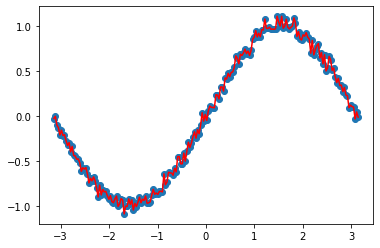

In [21]:
import numpy as np
import matplotlib.pyplot as plt
X = np.linspace(-np.pi,np.pi, 200)
Y=np.sin(X)
noise = 0.05 * np.random.normal(size = Y.shape[0])
Y=Y+noise
test_share = 0.2
i_all_data = np.arange(0,X.shape[0])
i_test_data = np.random.choice(i_all_data, size=int(X.shape[0]*test_share), replace = False)
i_training_data = np.delete(i_all_data, i_test_data)
X_train = X[i_training_data]
Y_train = Y[i_training_data]
X_test = X[i_test_data]
Y_test = Y[i_test_data]
plt.scatter(X,Y)
plt.plot(X,Y, color = "red")

Folie 61

In [22]:
import numpy as np
size_i = 1000
x = np.zeros(size_i)

for i in range(size_i):
    x[i] = i**2/size_i
print(x.sum())

i = np.arange(size_i)
x = i**2/size_i  
print(x.sum())

332833.5
332833.5


Folie 62

In [65]:
x,y = np.meshgrid(np.arange(5),np.arange(5), indexing ="ij")
x=x.astype("str")
y=y.astype("str")
x=np.char.add(x,",")
np.char.add(x,y)

array([['0,0', '0,1', '0,2', '0,3', '0,4'],
       ['1,0', '1,1', '1,2', '1,3', '1,4'],
       ['2,0', '2,1', '2,2', '2,3', '2,4'],
       ['3,0', '3,1', '3,2', '3,3', '3,4'],
       ['4,0', '4,1', '4,2', '4,3', '4,4']], dtype='<U43')

runtime (s): 11.631371021270752


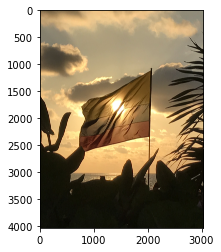

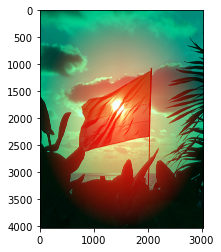

In [24]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import time

plt.figure(1)
colombia = mpimg.imread('colombia.png')
plt.imshow(colombia)
newcolombia = np.copy(colombia)

t = time.time()

len_i = len(newcolombia[:,0,0])
len_j = len(newcolombia[0,:,0])
for i in range(len_i):
    for j in range(len_j):
        newcolombia[i,j,0]=max(1-(i/(len_i/2)-1)**2- (j/(len_j/2)-1)**2,0)

run_time = time.time()-t
print("runtime (s): "+ str(run_time))        
        
plt.figure(2)
plt.imshow(newcolombia)

Folie 63: Bildverarbeitung

runtime (s): 0.3970820903778076


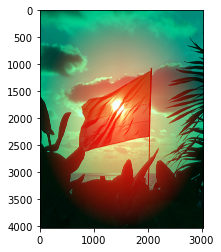

In [25]:
plt.figure(1)
colombia = mpimg.imread('colombia.png')
plt.imshow(colombia)
newcolombia = np.copy(colombia)
t = time.time()

len_i = len(newcolombia[:,0,0])
len_j = len(newcolombia[0,:,0])
i,j = np.meshgrid(np.arange(len_i),np.arange(len_j), indexing = 'ij')
newcolombia[:,:,0]=np.maximum(1-(i/(len_i/2)-1)**2- (j/(len_j/2)-1)**2,0)

#np.maximum for elementwise max != np.max 

run_time = time.time()-t
print("runtime (s): "+ str(run_time))    
plt.imshow(newcolombia) 

Folie 66

In [26]:
import pandas as pd
S = pd.Series([11, 28, 72, 3, 5, 8])
S

0    11
1    28
2    72
3     3
4     5
5     8
dtype: int64

In [28]:
S.values

array([11, 28, 72,  3,  5,  8], dtype=int64)

In [29]:
S.index

RangeIndex(start=0, stop=6, step=1)

In [30]:
type(S.values)

numpy.ndarray

Folie 67

In [31]:
fruits = ['apples', 'oranges', 'cherries', 'pears']
quantities = [20, 33, 52, 10]
S = pd.Series(quantities, index=fruits)
S

apples      20
oranges     33
cherries    52
pears       10
dtype: int64

In [32]:
fruits = ['peaches', 'oranges', 'cherries', 'pears']
fruits2 = ['raspberries', 'oranges', 'cherries', 'pears']
S1 = pd.Series([20, 33, 52, 10], index=fruits)
S2 = pd.Series([17, 13, 31, 32], index=fruits2)
S3 = S1 + S2
S3

cherries       83.0
oranges        46.0
peaches         NaN
pears          42.0
raspberries     NaN
dtype: float64

Folie 68

In [33]:
S3.isnull()

cherries       False
oranges        False
peaches         True
pears          False
raspberries     True
dtype: bool

In [34]:
S4=S3.dropna()
S4

cherries    83.0
oranges     46.0
pears       42.0
dtype: float64

In [35]:
S3.fillna(0)

cherries       83.0
oranges        46.0
peaches         0.0
pears          42.0
raspberries     0.0
dtype: float64

In [37]:
missing_fruits = {"peaches": 15, "raspberries":50}
S3.fillna(missing_fruits, inplace=True)
S3

cherries       83.0
oranges        46.0
peaches        15.0
pears          42.0
raspberries    50.0
dtype: float64

Folie 69

In [38]:
S3[["cherries", "peaches"]]

cherries    83.0
peaches     15.0
dtype: float64

In [39]:
S3[S3>40]

cherries       83.0
oranges        46.0
pears          42.0
raspberries    50.0
dtype: float64

In [40]:
S3.apply(lambda x: x**2)

cherries       6889.0
oranges        2116.0
peaches         225.0
pears          1764.0
raspberries    2500.0
dtype: float64

In [41]:
S3.apply(np.sqrt)

cherries       9.110434
oranges        6.782330
peaches        3.872983
pears          6.480741
raspberries    7.071068
dtype: float64

In [42]:
def polynom(x,a=1,b=1,c=1):
    return(a*x**2+b*x+c)
S3.apply(polynom, a=2, b = 35, c = 50)

cherries       16733.0
oranges         5892.0
peaches         1025.0
pears           5048.0
raspberries     6800.0
dtype: float64

Folie 70: Series aus einem Dictionary erstellen

In [43]:
cities = {"London":    8615246, 
          "Berlin":    3562166, 
          "Madrid":    3165235, 
          "Rome":      2874038, 
          "Paris":     2273305, 
          "Vienna":    1805681, 
          "Bucharest": 1803425, 
          "Hamburg":   1760433,
          "Budapest":  1754000,
          "Warsaw":    1740119,
          "Barcelona": 1602386,
          "Munich":    1493900,
          "Milan":     1350680}
city_series = pd.Series(cities)
print(city_series)

London       8615246
Berlin       3562166
Madrid       3165235
Rome         2874038
Paris        2273305
Vienna       1805681
Bucharest    1803425
Hamburg      1760433
Budapest     1754000
Warsaw       1740119
Barcelona    1602386
Munich       1493900
Milan        1350680
dtype: int64


Folie 71

In [44]:
years = range(2014, 2018)
shop1 = pd.Series([2409.14, 2941.01, 3496.83, 3119.55], index=years)
shop2 = pd.Series([1203.45, 3441.62, 3007.83, 3619.53], index=years)
shop3 = pd.Series([3412.12, 3491.16, 3457.19, 1963.10], index=years)
dt = pd.concat([shop1, shop2, shop3], axis=1)
dt

,0,1,2
2014,2409.14,1203.45,3412.12
2015,2941.01,3441.62,3491.16
2016,3496.83,3007.83,3457.19
2017,3119.55,3619.53,1963.10


Folie 72

In [45]:
dt.columns = ["Dortmund", "Gütersloh", "Bielefeld"]
dt

,Dortmund,Gütersloh,Bielefeld
2014,2409.14,1203.45,3412.12
2015,2941.01,3441.62,3491.16
2016,3496.83,3007.83,3457.19
2017,3119.55,3619.53,1963.10


In [46]:
dt["Dortmund"]

2014    2409.14
2015    2941.01
2016    3496.83
2017    3119.55
Name: Dortmund, dtype: float64

Folie 73: Data Frames und Generatoren

In [47]:
def expo(x, p, n):
    return x* (1+p/100)**n
city_series.apply(expo, p=1,n=5)

London       9.054710e+06
Berlin       3.743872e+06
Madrid       3.326694e+06
Rome         3.020643e+06
Paris        2.389266e+06
Vienna       1.897789e+06
Bucharest    1.895418e+06
Hamburg      1.850233e+06
Budapest     1.843472e+06
Warsaw       1.828883e+06
Barcelona    1.684124e+06
Munich       1.570104e+06
Milan        1.419578e+06
dtype: float64

London       <generator object expo at 0x0000023591722040>
Berlin       <generator object expo at 0x0000023591722120>
Madrid       <generator object expo at 0x00000235917220B0>
Rome         <generator object expo at 0x0000023591722190>
Paris        <generator object expo at 0x0000023591722200>
Vienna       <generator object expo at 0x0000023591722270>
Bucharest    <generator object expo at 0x00000235917222E0>
Hamburg      <generator object expo at 0x0000023591722350>
Budapest     <generator object expo at 0x00000235917223C0>
Warsaw       <generator object expo at 0x0000023591722430>
Barcelona    <generator object expo at 0x00000235917224A0>
Munich       <generator object expo at 0x0000023591722510>
Milan        <generator object expo at 0x0000023591722580>
dtype: object


C:\Users\chris\AppData\Local\Temp/ipykernel_19236/414641183.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead.  To get a de-fragmented frame, use `newframe = frame.copy()`
  population[i]  = a.apply(next)


<AxesSubplot:>

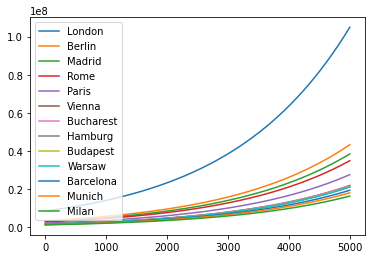

In [48]:
def expo(x, p):
    while (True):
        x = x* (1+p/100)
        yield x 
a = city_series.apply(expo, p=0.05)
print(a)
epocs = 5000
population = pd.DataFrame()
for i in range(epocs):
    population[i]  = a.apply(next)
    
#print(population)
population.T.plot()

Folie 74: Data Frames und Generatoren

In [49]:
cities = {"Name":['London', 'Berlin', 'Madrid', 'Rome', 'Paris', 'Vienna'],
          "Population":[8615246, 3562166, 3165235, 2874038, 2273305, 1805681],
         "Country":['England', 'Germany', 'Spain', 'Italy', 'France', 'Austria']}
city_series = pd.DataFrame(cities)
city_series

,Name,Population,Country
0,London,8615246,England
1,Berlin,3562166,Germany
2,Madrid,3165235,Spain
3,Rome,2874038,Italy
4,Paris,2273305,France
5,Vienna,1805681,Austria


Folie 76

In [50]:
city_series["Country"]

0    England
1    Germany
2      Spain
3      Italy
4     France
5    Austria
Name: Country, dtype: object

In [52]:
city_frame = pd.DataFrame(cities)
city_frame.set_index("Country", inplace=True)
city_frame
city_frame.loc[["Germany","France"]]

,Name,Population
Country,,
Germany,Berlin,3562166
France,Paris,2273305


In [53]:
city_frame.loc[city_frame.Population > 3400000]

,Name,Population
Country,,
England,London,8615246
Germany,Berlin,3562166


In [54]:
city_frame.sort_values(by = "Population", ascending=True)

,Name,Population
Country,,
Austria,Vienna,1805681
France,Paris,2273305
Italy,Rome,2874038
Spain,Madrid,3165235
Germany,Berlin,3562166
England,London,8615246


Folie 77: Data Frames - Zugriff auf die Daten

In [55]:
area = [1572, 891.85, 605.77, 1285, 
        105.4, 414.6]
city_frame.insert(loc = 1, column="Area", value= area)
city_frame.sort_values(by = "Area", ascending=True)

,Name,Area,Population
Country,,,
France,Paris,105.40,2273305
Austria,Vienna,414.60,1805681
Spain,Madrid,605.77,3165235
Germany,Berlin,891.85,3562166
Italy,Rome,1285.00,2874038
England,London,1572.00,8615246


Folie 78

In [57]:
studies = pd.read_csv("C:\\0 Eigene Dateien\\9 Lehre\\2019 Einführung in Data Science\\4. Veranstaltung\\Studium.csv", sep=";")
studies

,Matrikelnummer,Vorname,Nachname,Alter,Studiengangsnummer,Studiengang,Studiengangsleitung,Gruendungsjahr
0,1002,Berta,Gross,20,1,Digitale Technologien,Stefan Berlik,2018
1,1111,Magnus,Meier,22,3,Product Service Engineering,Peter Rauer,2018
2,1111,Magnus,Meier,22,1,Digitale Technologien,Stefan Berlik,2018
3,1231,Petra,Paulis,21,2,Digitale Logistik,Joerg Nottmeyer,2017
4,1432,Christian,Liebler,19,1,Digitale Technologien,Stefan Berlik,2018
5,1511,Werner,Wal,20,1,Digitale Technologien,Stefan Berlik,2018
6,1512,Herbert,Klein,22,3,Product Service Engineering,Peter Rauer,2018
7,1513,Markus,Meier,20,2,Digitale Logistik,Joerg Nottmeyer,2017
8,1513,Markus,Meier,20,1,Digitale Technologien,Stefan Berlik,2018
9,1567,Meike,Moser,19,2,Digitale Logistik,Joerg Nottmeyer,2017


In [58]:
city_frame.to_csv("C:\\0 Eigene Dateien\\9 Lehre\\2019 Einführung in Data Science\\4. Veranstaltung\\Städte.csv", sep = ";")